# Groceries shop

# Connection to PostgreSQL

In [1]:
import os
from getpass import getpass

import pandas as pd
from sqlalchemy import create_engine

# Credentials are read from environment variables so they are never stored in the notebook.
# If PGPASSWORD is not set, the password is requested interactively.
USER = os.getenv("PGUSER", "postgres")
PASSWORD = os.getenv("PGPASSWORD") or getpass("PostgreSQL password: ")
HOST = os.getenv("PGHOST", "localhost")
PORT = os.getenv("PGPORT", "5432")
DB = os.getenv("PGDATABASE", "groceries_db")

engine = create_engine(f"postgresql+psycopg2://{USER}:{PASSWORD}@{HOST}:{PORT}/{DB}")

# create_engine() is lazy: open one connection now so bad credentials fail here, not mid-notebook.
with engine.connect() as conn:
    print("Successful connection to PostgreSQL")

Successful connection to PostgreSQL


In [2]:
# Plot style shared by every chart in the notebook
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator

%config InlineBackend.figure_format = "retina"

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_SECONDARY, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, BASELINE = "#fcfcfb", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.titlesize": 14,
    "axes.titleweight": "semibold",
    "axes.titlelocation": "left",
    "axes.labelcolor": INK_SECONDARY,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "font.size": 11,
})

millions = FuncFormatter(lambda x, _: f"{x / 1e6:,.0f}M")

# Typical queries performed by a Data Scientist

## A) Dataset overview

The fact table has ~6.7M rows, so every aggregation runs inside PostgreSQL and only the result is brought into pandas.

In [3]:
df_overview = pd.read_sql("""
SELECT
    COUNT(*)                            AS sales_lines,
    COUNT(DISTINCT CustomerID)          AS customers,
    COUNT(DISTINCT ProductID)           AS products,
    COUNT(DISTINCT EmployeeID)          AS employees,
    MIN(date)                           AS first_date,
    MAX(date)                           AS last_date,
    COUNT(DISTINCT date)                AS days_with_sales,
    SUM(Quantity)                       AS units_sold,
    SUM(revenue)                        AS total_revenue,
    COUNT(*) FILTER (WHERE date IS NULL) AS rows_without_date
FROM analytics.fact_sales
""", engine)

df_overview.T

,0
sales_lines,6758125
customers,98759
products,452
employees,23
first_date,2018-01-01
last_date,2018-05-09
days_with_sales,129
units_sold,87882708
total_revenue,4332446453.51
rows_without_date,67526


In [4]:
# Average ticket per visit
# Every TransactionNumber holds a single product line, so a visit is defined as a customer-day
df_ticket = pd.read_sql("""
SELECT
    COUNT(*)                   AS visits,
    ROUND(AVG(visit_total), 2) AS average_ticket,
    ROUND(AVG(visit_lines), 2) AS average_lines_per_visit
FROM (
    SELECT
        CustomerID,
        date,
        SUM(revenue) AS visit_total,
        COUNT(*)     AS visit_lines
    FROM analytics.fact_sales
    WHERE date IS NOT NULL
    GROUP BY CustomerID, date
) v
""", engine)

df_ticket

,visits,average_ticket,average_lines_per_visit
0,5203059,824.37,1.29


In [5]:
df_products = pd.read_sql("""
SELECT *
FROM analytics.dim_product
""", engine)

df_products.head()

,productid,productname,price,categoryid,categoryname,class,resistant,isallergic,vitalitydays
0,451,Soup - Campbells Tomato Ravioli,93.5384,1,Confections,Low,Durable,False,0.0
1,440,Pork - Inside,32.9092,1,Confections,Low,Unknown,Unknown,0.0
2,404,Pants Custom Dry Clean,65.0280,1,Confections,Medium,Durable,False,0.0
3,400,Carbonated Water - Blackcherry,18.1495,1,Confections,High,Durable,True,0.0
4,397,Juice - Happy Planet,20.8169,1,Confections,Medium,Weak,False,70.0


## B) Materialized views (fast analytics)

In [6]:
df_top_products = pd.read_sql("""
SELECT *
FROM analytics.mv_top_products
""", engine)

df_top_products.head(10)

,productid,productname,categoryname,total_revenue,total_units_sold
0,345,Bread - Calabrese Baguette,Dairy,18868840.18,197257
1,98,Shrimp - 31/40,Cereals,18721948.19,193234
2,392,Puree - Passion Fruit,Beverages,18703480.58,194957
3,104,Tia Maria,Beverages,18685125.46,196210
4,149,Zucchini - Yellow,Snails,18551658.32,194209
5,268,Vanilla Beans,Poultry,18530395.64,195273
6,248,Beef - Inside Round,Meat,18334982.76,190684
7,201,Grenadine,Grain,18331170.17,196031
8,32,Lettuce - Treviso,Cereals,18321890.83,195942
9,298,Pop Shoppe Cream Soda,Dairy,18241372.29,196352


In [7]:
df_monthly_sales = pd.read_sql("""
SELECT *
FROM analytics.mv_sales_monthly_category
ORDER BY year_month, categoryname
""", engine)

df_monthly_sales

,year_month,categoryname,monthly_revenue
0,2018-01,Beverages,8.704492e+07
1,2018-01,Cereals,1.012021e+08
2,2018-01,Confections,1.328152e+08
3,2018-01,Dairy,8.404103e+07
4,2018-01,Grain,7.737905e+07
5,2018-01,Meat,1.171268e+08
6,2018-01,Poultry,1.047797e+08
7,2018-01,Produce,8.745322e+07
8,2018-01,Seafood,7.865611e+07
9,2018-01,Shell fish,7.128779e+07


## C) Exploratory Data Analysis

In [8]:
# The data ends on 2018-05-09, so May is a partial month: revenue per day with sales compares months fairly
df_monthly = pd.read_sql("""
SELECT
    TO_CHAR(fs.date, 'YYYY-MM') AS year_month,
    SUM(fs.revenue) AS monthly_revenue,
    COUNT(DISTINCT fs.date) AS days_with_sales,
    SUM(fs.revenue) / COUNT(DISTINCT fs.date) AS avg_daily_revenue
FROM analytics.fact_sales fs
WHERE fs.date IS NOT NULL
GROUP BY 1
ORDER BY 1
""", engine)

df_monthly

,year_month,monthly_revenue,days_with_sales,avg_daily_revenue
0,2018-01,1.030736e+09,31,3.324955e+07
1,2018-02,9.292044e+08,28,3.318587e+07
2,2018-03,1.032201e+09,31,3.329681e+07
3,2018-04,9.972687e+08,30,3.324229e+07
4,2018-05,2.998325e+08,9,3.331472e+07


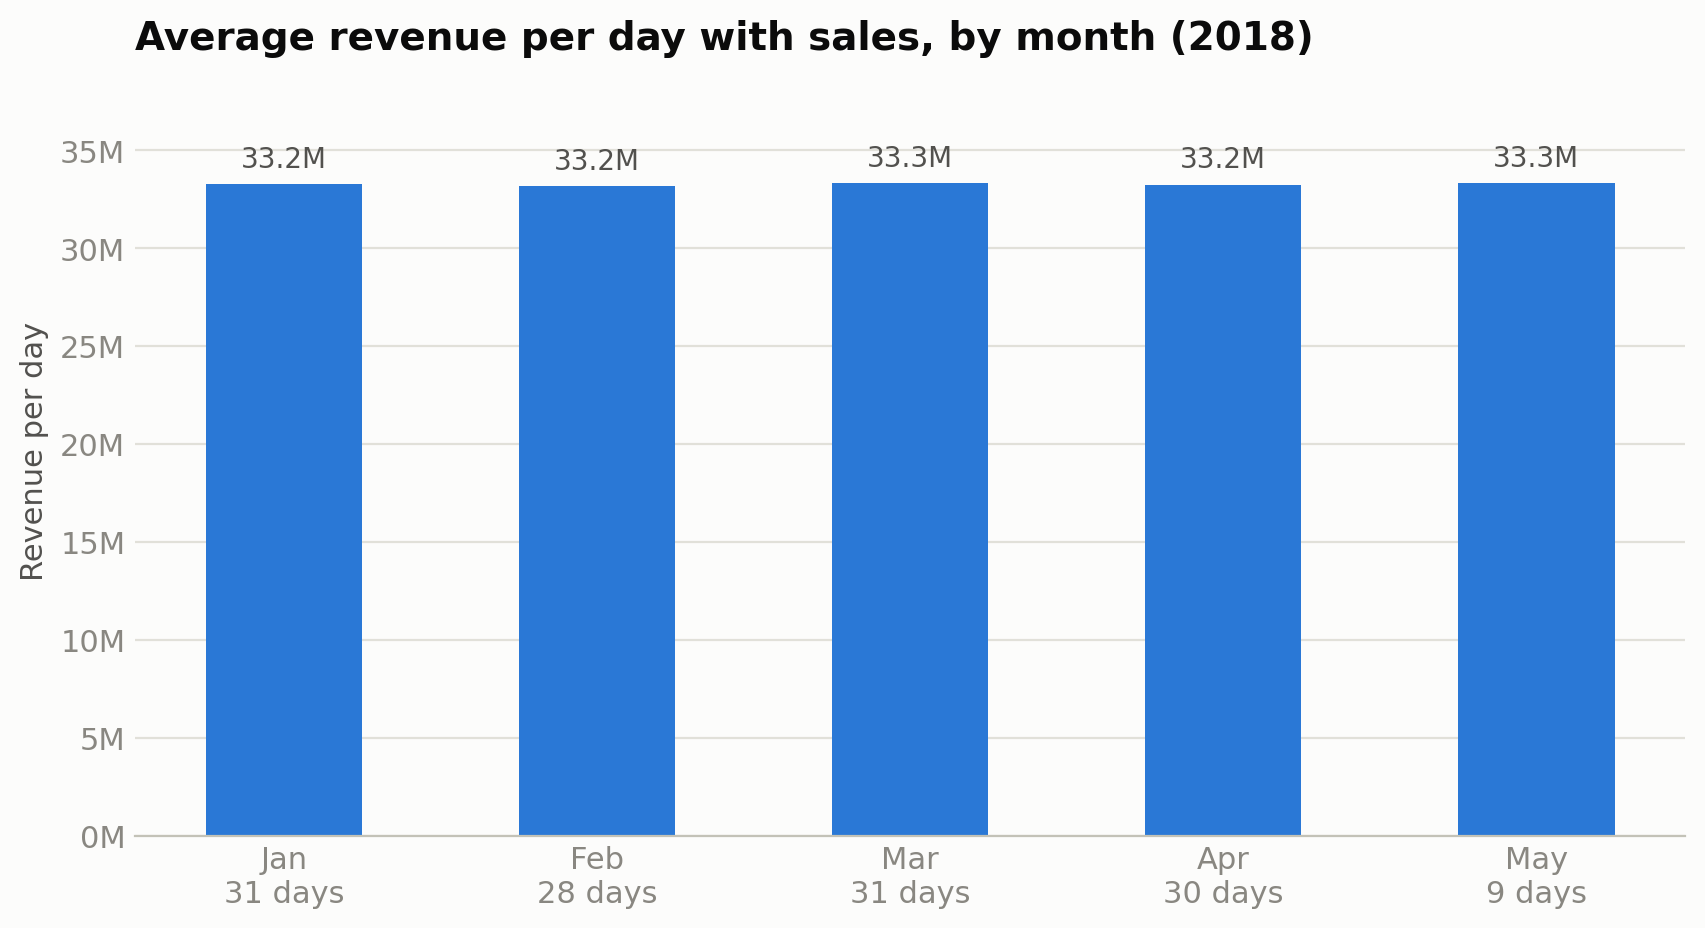

In [9]:
fig, ax = plt.subplots()
labels = [f"{pd.Timestamp(m + '-01'):%b}\n{d} days" for m, d in zip(df_monthly["year_month"], df_monthly["days_with_sales"])]
bars = ax.bar(labels, df_monthly["avg_daily_revenue"], width=0.5, color=BLUE)
ax.bar_label(bars, labels=[f"{v / 1e6:,.1f}M" for v in df_monthly["avg_daily_revenue"]],
             padding=4, color=INK_SECONDARY, fontsize=10)
ax.yaxis.set_major_formatter(millions)
ax.grid(axis="x", visible=False)
ax.set_ylim(0, df_monthly["avg_daily_revenue"].max() * 1.18)
ax.set_title("Average revenue per day with sales, by month (2018)")
ax.set_ylabel("Revenue per day")
plt.show()

In [10]:
df_category_sales = pd.read_sql("""
SELECT
    p.CategoryName,
    SUM(fs.revenue) AS revenue,
    ROUND(100.0 * SUM(fs.revenue) / SUM(SUM(fs.revenue)) OVER (), 1) AS revenue_share_pct
FROM analytics.fact_sales fs
JOIN analytics.dim_product p
    ON fs.ProductID = p.ProductID
GROUP BY 1
ORDER BY revenue DESC
""", engine)

df_category_sales

,categoryname,revenue,revenue_share_pct
0,Confections,5.569308e+08,12.9
1,Meat,4.928889e+08,11.4
2,Poultry,4.400256e+08,10.2
3,Cereals,4.273935e+08,9.9
4,Snails,3.720850e+08,8.6
5,Produce,3.682437e+08,8.5
6,Beverages,3.665152e+08,8.5
7,Dairy,3.543582e+08,8.2
8,Seafood,3.305280e+08,7.6
9,Grain,3.238792e+08,7.5


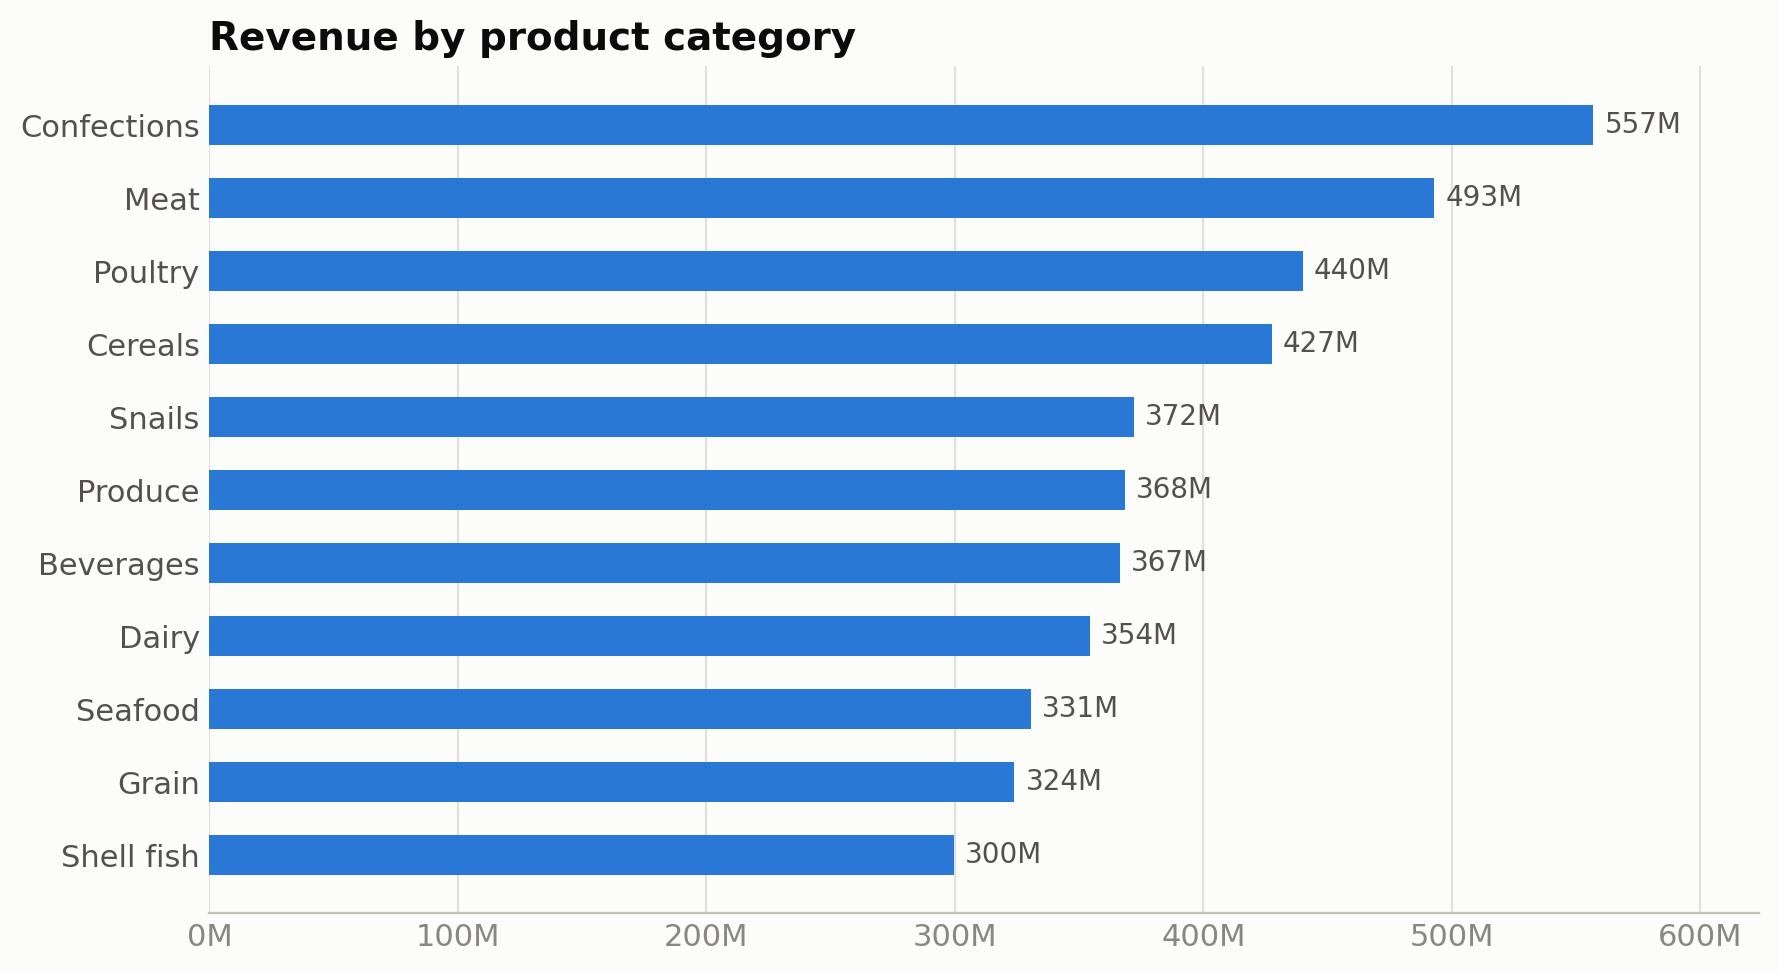

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.5))
data = df_category_sales.sort_values("revenue")
bars = ax.barh(data["categoryname"], data["revenue"], height=0.55, color=BLUE)
ax.bar_label(bars, labels=[f"{v / 1e6:,.0f}M" for v in data["revenue"]], padding=4, color=INK_SECONDARY, fontsize=10)
ax.xaxis.set_major_formatter(millions)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, data["revenue"].max() * 1.12)
ax.tick_params(axis="y", colors=INK_SECONDARY)
ax.set_title("Revenue by product category")
plt.show()

In [12]:
df_top_customers = pd.read_sql("""
SELECT
    fs.CustomerID,
    SUM(fs.revenue) AS total_revenue
FROM analytics.fact_sales fs
GROUP BY fs.CustomerID
ORDER BY total_revenue DESC
LIMIT 20
""", engine)

df_top_customers

,customerid,total_revenue
0,94800,130324.12
1,95972,123004.95
2,97863,121922.67
3,95048,121884.08
4,95157,120849.92
5,94138,119853.87
6,97813,119418.79
7,96775,119180.37
8,95971,118687.78
9,95868,118624.65


## D) Product analytics

In [13]:
df_best_products = pd.read_sql("""
SELECT
    fs.ProductID,
    p.ProductName,
    SUM(fs.Quantity) AS total_units_sold
FROM analytics.fact_sales fs
JOIN analytics.dim_product p
    ON fs.ProductID = p.ProductID
GROUP BY fs.ProductID, p.ProductName
ORDER BY total_units_sold DESC
LIMIT 20
""", engine)

df_best_products

,productid,productname,total_units_sold
0,179,Yoghurt Tubes,199724
1,161,Longos - Chicken Wings,199679
2,47,"Thyme - Lemon, Fresh",198567
3,280,Onion Powder,198163
4,103,Cream Of Tartar,198126
5,324,Apricots - Dried,198032
6,39,Dried Figs,198032
7,319,Towels - Paper / Kraft,198005
8,425,Wine - Redchard Merritt,197969
9,184,Hersey Shakes,197942


## E) Customer segmentation (RFM)

`analytics.v_customer_rfm` (defined in `03_rfm_cohort.sql`) scores every customer by recency, frequency (visits = customer-days) and monetary value, with 1 as the best quintile, and maps the scores to business segments.

In [14]:
df_rfm = pd.read_sql("""
SELECT *
FROM analytics.v_customer_rfm
""", engine)

df_rfm[["recency_days", "frequency", "monetary"]].describe().round(2)

,recency_days,frequency,monetary
count,98759.00,98759.00,98759.00
mean,1.45,52.68,43868.88
std,1.89,5.57,25307.34
min,0.00,31.00,1971.24
25%,0.00,49.00,22299.18
50%,1.00,53.00,42970.21
75%,2.00,56.00,63836.52
max,21.00,77.00,130324.12


In [15]:
# Segment summary: how many customers each segment has and how much revenue it brings
df_segments = (
    df_rfm.groupby("rfm_segment")
    .agg(customers=("customerid", "count"),
         revenue=("monetary", "sum"),
         avg_recency_days=("recency_days", "mean"),
         avg_visits=("frequency", "mean"),
         avg_monetary=("monetary", "mean"))
    .assign(pct_customers=lambda d: 100 * d["customers"] / d["customers"].sum(),
            pct_revenue=lambda d: 100 * d["revenue"] / d["revenue"].sum())
    .sort_values("pct_revenue", ascending=False)
    .round(1)
)

df_segments

,customers,revenue,avg_recency_days,avg_visits,avg_monetary,pct_customers,pct_revenue
rfm_segment,,,,,,,
Need Attention,29696,1.340586e+09,1.2,50.9,45143.7,30.1,30.9
At Risk,15319,7.141088e+08,2.7,57.9,46615.9,15.5,16.5
Hibernating,15872,6.081505e+08,3.7,47.1,38315.9,16.1,14.0
Champions,7859,5.832882e+08,0.0,58.8,74219.1,8.0,13.5
Loyal Customers,16326,5.467604e+08,0.4,57.9,33490.2,16.5,12.6
New / Promising,13687,5.395524e+08,0.0,47.6,39420.8,13.9,12.5


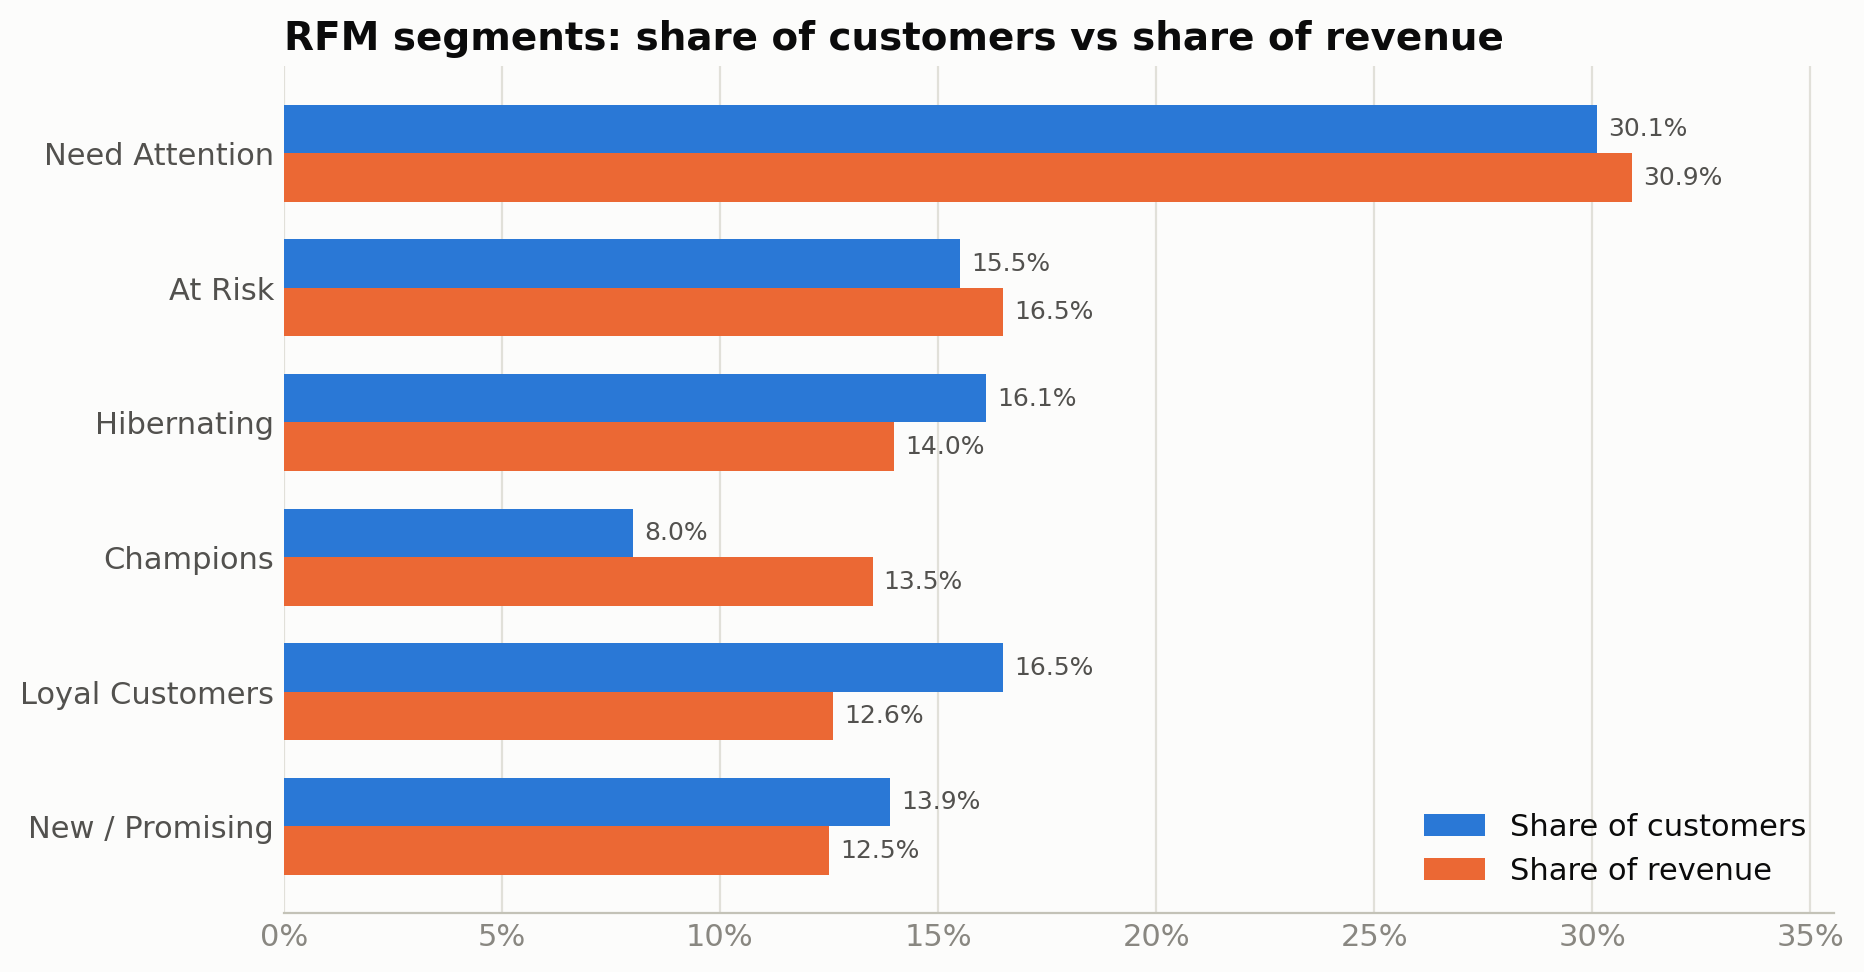

In [16]:
fig, ax = plt.subplots(figsize=(10, 5.5))
data = df_segments.sort_values("pct_revenue")
y = range(len(data))
h = 0.36
b1 = ax.barh([i + h / 2 for i in y], data["pct_customers"], height=h, color=BLUE, label="Share of customers")
b2 = ax.barh([i - h / 2 for i in y], data["pct_revenue"], height=h, color=ORANGE, label="Share of revenue")
for bars in (b1, b2):
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in bars.datavalues], padding=4, color=INK_SECONDARY, fontsize=9)
ax.set_yticks(list(y), data.index, color=INK_SECONDARY)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(data["pct_customers"].max(), data["pct_revenue"].max()) * 1.15)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax.legend(loc="lower right", frameon=False)
ax.set_title("RFM segments: share of customers vs share of revenue")
plt.show()

## F) Cohort retention

In [17]:
df_cohorts = pd.read_sql("""
SELECT *
FROM analytics.v_cohort_retention
ORDER BY cohort_month, month_number
""", engine)

df_cohorts

,cohort_month,order_month,month_number,customers,cohort_size,retention_pct
0,2018-01-01,2018-01-01,0,98759,98759,100.0
1,2018-01-01,2018-02-01,1,98759,98759,100.0
2,2018-01-01,2018-03-01,2,98759,98759,100.0
3,2018-01-01,2018-04-01,3,98759,98759,100.0
4,2018-01-01,2018-05-01,4,97866,98759,99.1


## G) Market basket analysis

A basket is every product bought by the same customer on the same day. `analytics.mv_product_pairs` stores support, confidence and lift for every product pair. Lift compares observed co-purchases with the count expected by chance given the real basket sizes.

In [18]:
df_pairs = pd.read_sql("""
SELECT product_a, product_b, times_bought_together, expected_together, support, confidence_a_to_b, lift
FROM analytics.mv_product_pairs
""", engine)

df_pairs.sort_values("lift", ascending=False).head(10)

,product_a,product_b,times_bought_together,expected_together,support,confidence_a_to_b,lift
32368,Cheese - Wine,Eggplant - Asian,39,17.29,0.000007,0.0026,2.2550
74741,Longos - Grilled Salmon With Bbq,Onion Powder,37,17.49,0.000007,0.0025,2.1154
50570,Extract - Lemon,Fenngreek Seed,36,17.12,0.000007,0.0024,2.1024
82758,Puree - Mocha,Smoked Paprika,35,16.95,0.000007,0.0024,2.0650
90350,General Purpose Trigger,"Chicken - Leg, Boneless",35,17.18,0.000007,0.0024,2.0374
64646,Cookies - Assorted,Hersey Shakes,35,17.50,0.000007,0.0024,2.0001
13068,Yeast Dry - Fermipan,Apricots - Halves,34,17.01,0.000007,0.0023,1.9994
62442,Milk - 2%,"Shrimp - Baby, Warm Water",34,17.07,0.000007,0.0023,1.9917
28086,Scampi Tail,Wine - Pinot Noir Latour,34,17.10,0.000007,0.0023,1.9878
48493,"Veal - Inside, Choice",Flour - Pastry,34,17.11,0.000007,0.0023,1.9871


In [19]:
# Is lift calibrated? Across all pairs, observed co-purchases should match the expectation under chance
pd.Series({
    "product_pairs": len(df_pairs),
    "observed_over_expected_all_pairs": df_pairs["times_bought_together"].sum() / df_pairs["expected_together"].sum(),
    "expected_together_min": df_pairs["expected_together"].min(),
    "expected_together_max": df_pairs["expected_together"].max(),
    "median_lift": df_pairs["lift"].median(),
    "lift_p05": df_pairs["lift"].quantile(0.05),
    "lift_p95": df_pairs["lift"].quantile(0.95),
}).round(3)

product_pairs                       101926.000
observed_over_expected_all_pairs         1.002
expected_together_min                   16.530
expected_together_max                   18.070
median_lift                              0.992
lift_p05                                 0.635
lift_p95                                 1.412
dtype: float64

In [20]:
# Multiple comparisons: with ~100k pairs, some will look strong by pure chance.
# Exact Poisson tail P(X >= observed | expected) for the top pairs, with a Bonferroni correction.
import math

def poisson_sf(k, mu):
    """P(X >= k) for X ~ Poisson(mu)."""
    return 1 - sum(math.exp(-mu + i * math.log(mu) - math.lgamma(i + 1)) for i in range(int(k)))

top = df_pairs.nlargest(5, "lift").copy()
top["p_value"] = [poisson_sf(o, e) for o, e in zip(top["times_bought_together"], top["expected_together"])]
top["p_bonferroni"] = (top["p_value"] * len(df_pairs)).clip(upper=1)
top[["product_a", "product_b", "times_bought_together", "expected_together", "lift", "p_value", "p_bonferroni"]]

,product_a,product_b,times_bought_together,expected_together,lift,p_value,p_bonferroni
32368,Cheese - Wine,Eggplant - Asian,39,17.29,2.2550,0.000005,0.505842
74741,Longos - Grilled Salmon With Bbq,Onion Powder,37,17.49,2.1154,0.000032,1.000000
50570,Extract - Lemon,Fenngreek Seed,36,17.12,2.1024,0.000046,1.000000
82758,Puree - Mocha,Smoked Paprika,35,16.95,2.0650,0.000082,1.000000
90350,General Purpose Trigger,"Chicken - Leg, Boneless",35,17.18,2.0374,0.000106,1.000000


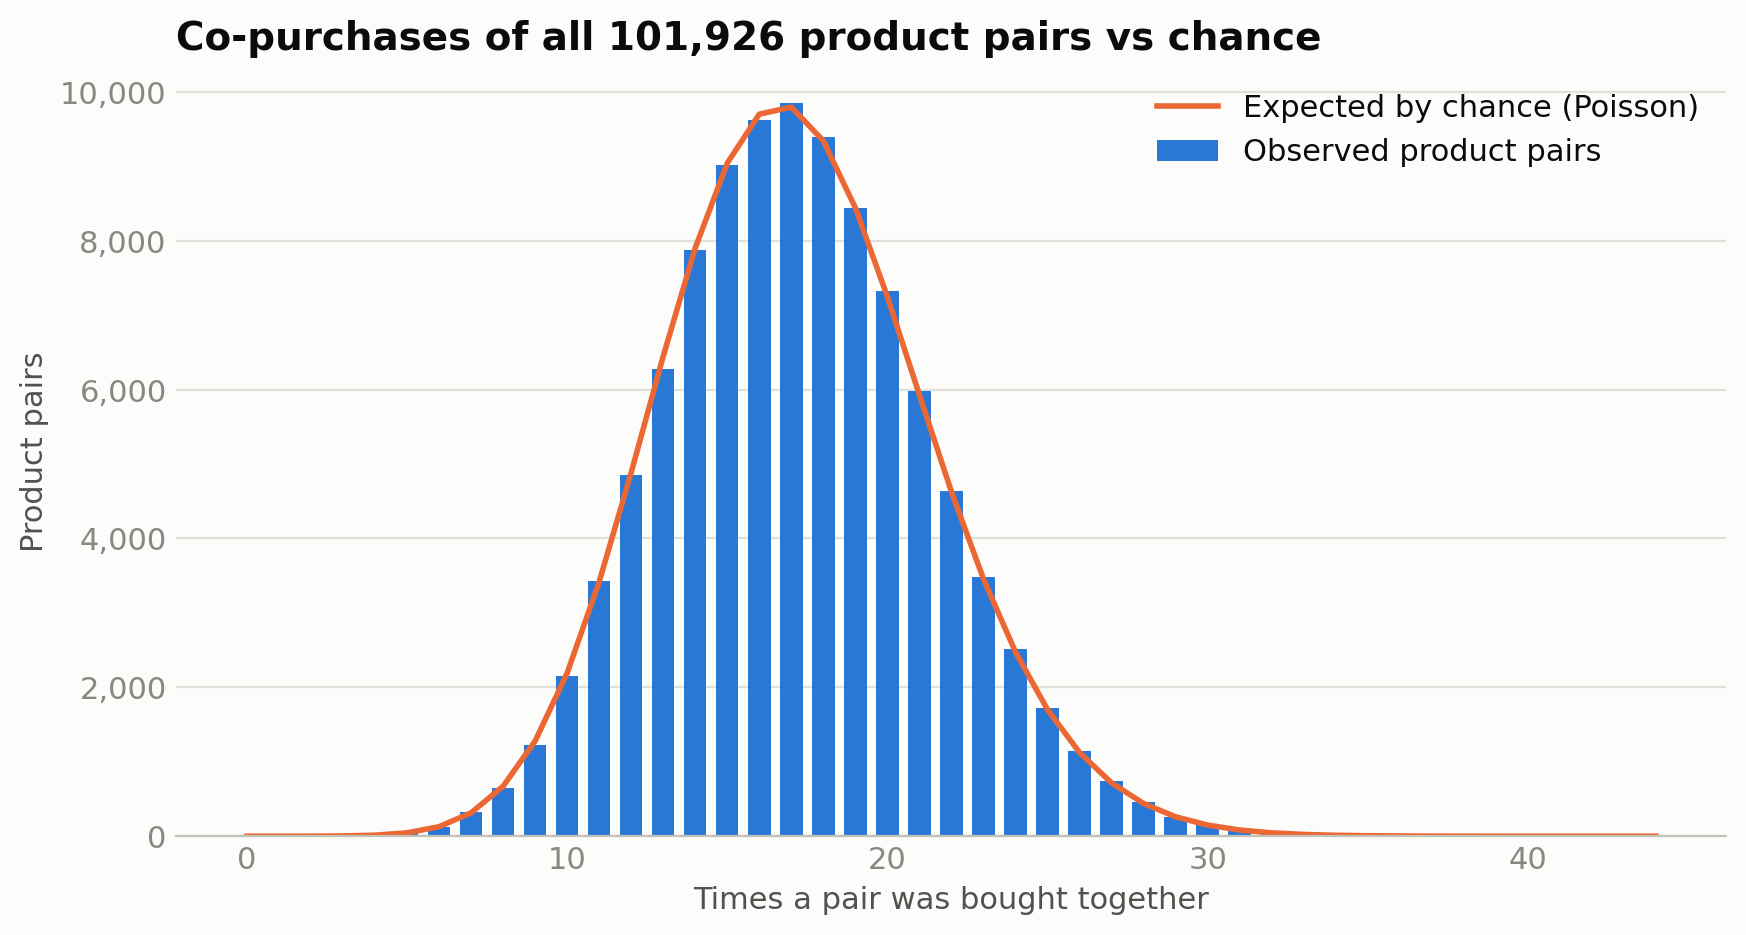

In [21]:
# Observed co-purchase counts per pair vs the distribution expected by chance:
# each pair's count should follow a Poisson distribution with its own expected value
import numpy as np

counts = df_pairs["times_bought_together"].value_counts().sort_index()
k = np.arange(0, counts.index.max() + 6)
mu = df_pairs["expected_together"].to_numpy(dtype=float)
expected_pairs = [np.exp(-mu + i * np.log(mu) - math.lgamma(i + 1)).sum() for i in k]

fig, ax = plt.subplots()
ax.bar(counts.index, counts.values, width=0.7, color=BLUE, label="Observed product pairs")
ax.plot(k, expected_pairs, color=ORANGE, linewidth=2, label="Expected by chance (Poisson)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.grid(axis="x", visible=False)
ax.set_xlabel("Times a pair was bought together")
ax.set_ylabel("Product pairs")
ax.legend(frameon=False)
ax.set_title(f"Co-purchases of all {len(df_pairs):,} product pairs vs chance")
plt.show()

## H) Customer behavior

In [22]:
# Gaps are aggregated in the database (one row per gap length) instead of returning
# one row per visit, which would be millions of rows.
df_interorder = pd.read_sql("""
WITH customer_days AS (
    -- One row per customer and purchase day: several products bought the same day are the same visit
    SELECT DISTINCT
        CustomerID,
        date
    FROM analytics.fact_sales
    WHERE date IS NOT NULL
),
gaps AS (
    SELECT
        date - LAG(date) OVER (PARTITION BY CustomerID ORDER BY date) AS days_between_visits
    FROM customer_days
)
SELECT
    days_between_visits,
    COUNT(*) AS visits
FROM gaps
WHERE days_between_visits IS NOT NULL
GROUP BY days_between_visits
ORDER BY days_between_visits
""", engine)

gaps = df_interorder.loc[df_interorder.index.repeat(df_interorder["visits"]), "days_between_visits"]
pd.Series({"repeat_visits": int(df_interorder["visits"].sum()),
           "median_days": gaps.median(),
           "mean_days": round(gaps.mean(), 2),
           "pct_next_day": round(100 * (gaps == 1).mean(), 1),
           "max_days": gaps.max()})

repeat_visits    5104300.00
median_days            2.00
mean_days              2.42
pct_next_day          41.30
max_days              31.00
dtype: float64

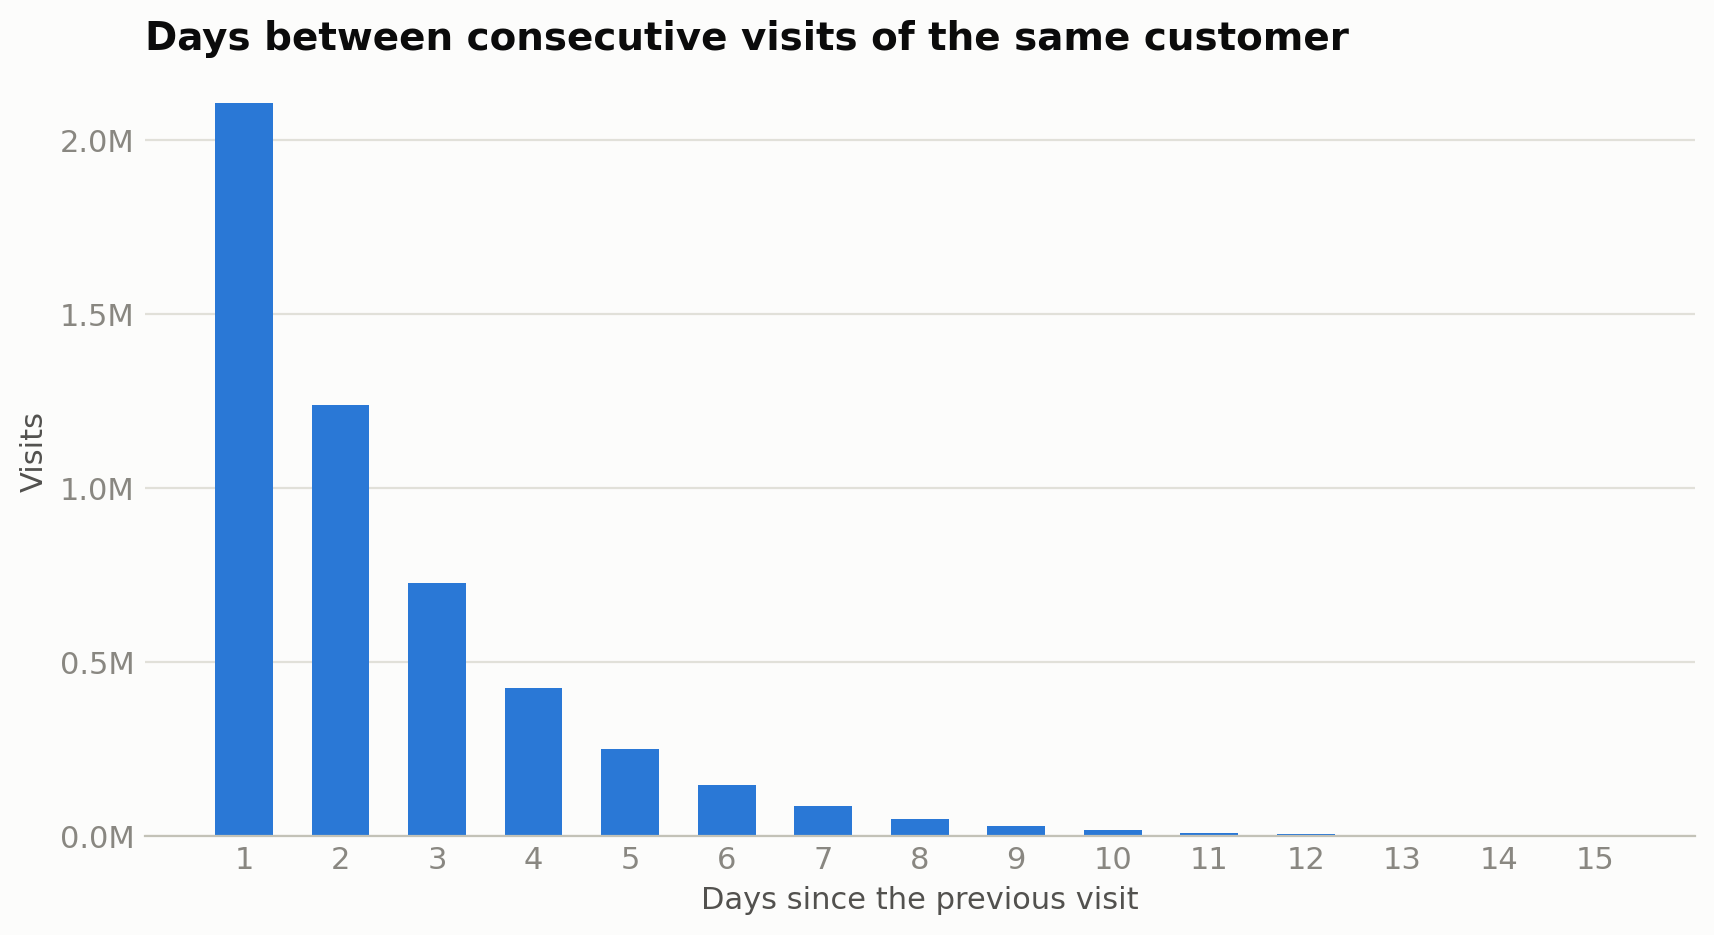

In [23]:
fig, ax = plt.subplots()
data = df_interorder[df_interorder["days_between_visits"] <= 15]
ax.bar(data["days_between_visits"], data["visits"], width=0.6, color=BLUE)
ax.yaxis.set_major_locator(MultipleLocator(500_000))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e6:.1f}M"))
ax.set_xticks(data["days_between_visits"])
ax.grid(axis="x", visible=False)
ax.set_xlabel("Days since the previous visit")
ax.set_ylabel("Visits")
ax.set_title("Days between consecutive visits of the same customer")
plt.show()

## I) Data Quality Checks

In [24]:
df_missing = pd.read_sql("""
SELECT
    COUNT(*) FILTER (WHERE revenue IS NULL) AS missing_revenue,
    COUNT(*) FILTER (WHERE quantity IS NULL) AS missing_quantity,
    COUNT(*) FILTER (WHERE date IS NULL) AS missing_date,
    COUNT(*) FILTER (WHERE ProductID IS NULL) AS missing_product,
    COUNT(*) FILTER (WHERE CustomerID IS NULL) AS missing_customer
FROM analytics.fact_sales
""", engine)

df_missing

,missing_revenue,missing_quantity,missing_date,missing_product,missing_customer
0,0,0,67526,0,0


In [25]:
df_duplicates = pd.read_sql("""
SELECT
    SalesID,
    COUNT(*)
FROM analytics.fact_sales
GROUP BY SalesID
HAVING COUNT(*) > 1
""", engine)

df_duplicates

,salesid,count


## J) BI-ready outputs

The curated tables for Tableau live in `2) Results ready for tableau/` and are exported with psql `\copy`. This check reconciles the Tableau views with the fact table.

In [26]:
df_reconciliation = pd.read_sql("""
SELECT
    (SELECT SUM(revenue) FROM analytics.fact_sales)                   AS fact_sales_revenue,
    (SELECT SUM(revenue) FROM analytics.v_tableau_sales)              AS v_tableau_sales_revenue,
    -- The monthly view only includes dated sales, so it differs by the revenue of the undated rows
    (SELECT SUM(total_revenue) FROM analytics.v_tableau_sales_monthly) AS v_tableau_sales_monthly_revenue,
    (SELECT SUM(revenue) FROM analytics.fact_sales WHERE date IS NULL) AS undated_revenue
""", engine)

df_reconciliation.T

,0
fact_sales_revenue,4.332446e+09
v_tableau_sales_revenue,4.332446e+09
v_tableau_sales_monthly_revenue,4.289243e+09
undated_revenue,4.320383e+07
